# 9장. 회귀 분석으로 숫자 예측하기

이 Notebook의 핵심은 높은 점수를 만드는 것이 아니라 다음 순서를 지키는 것입니다.

`예측 시점 → 누수 방지 → 시간 분할 → Train TimeSeriesSplit → 모델 선택 고정 → Final Test → Baseline 비교`

**Final Test 결과를 보고 모델을 고르지 않습니다.**

## 실행 전 예측 문제·선택 규칙 고정
- Target: order_total, 같은 order_id의 quantity×unit_price 합계(원).
- 예측 단위: 주문 1건. 전체 300건을 대상으로 하며 Chapter08과 달리 completed 주문만으로 필터링하지 않는다.
- 예측 시점: 결제수단을 선택하여 주문 메타데이터와 등록 프로필은 있지만 주문 상세 수량·단가·금액은 모델에 전달되지 않은 교육용 시점.
- 알 수 있는 정보: 주문 월·요일, 등록 나이·성별·도시, 선택한 결제수단.
- 알 수 없는 정보: 상세 수량·가격·금액과 그 파생 집계, 최종 주문 상태.
### 나의 해석과 판단
Target을 직접 계산하는 재료 없이 사전 정보만으로 미래 주문 금액을 추정하는 문제로 고정했다. 실제 서비스에서 결제수단이나 프로필을 그 시점에 조회할 수 없다면 해당 Feature도 제외해야 한다. 특히 이 문제는 장바구니가 확정되어 금액이 이미 알려진 상황과는 다르다. 원본에는 프로필 변경 이력이 없어 나이·도시의 시점 일치도는 교육용 가정이며 실제 배포 전 확인해야 한다.


후보는 공식 Baseline Mean / Linear Regression / Random Forest, seed=42, Train TimeSeriesSplit 5-fold다. 비베이스라인 CV MAE 최소 모델을 선택하고 Test 결과로 바꾸지 않는다.

## 0. 실행 전 확인

Chapter09는 Chapter05의 오류 탐지용 전용 Raw가 아니라 **공통 프로젝트 `data/raw`**를 사용합니다. 먼저 프로젝트 루트에서 다음 명령을 실행해 관계 검증을 통과한 모델링 입력을 준비합니다.

```powershell
python scripts/prepare_ch09_data.py
```

이 명령은 공통 `data/raw`를 전처리하고 FK 관계를 검증한 뒤 `data/processed/*_clean.csv`를 생성합니다.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np

def find_chapter_root(start):
    for candidate in [start, start / "chapter09", *start.parents]:
        if (candidate / "source_manifest.json").exists() and (candidate / "src/regression.py").exists():
            return candidate.resolve()
    raise FileNotFoundError("chapter09 폴더에서 Notebook을 열어 실행하세요.")

PROJECT_ROOT = find_chapter_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
REPORT_DIR = PROJECT_ROOT / "reports"
sys.path.insert(0, str(PROJECT_ROOT))
from scripts.prepare_ch09_data import prepare_ch09_data
prepared = prepare_ch09_data()
print("Input preparation: PASS")
display(prepared["relationship_checks"])
from src.regression import (
    FEATURE_COLUMNS, FORBIDDEN_FEATURES, TARGET_COLUMN, build_feature_audit,
    build_leakage_checklist, build_regression_dataset, build_regression_validation,
    build_split_summary, create_prediction_result, cross_validate_regression_models,
    load_regression_source_data, make_regression_models, run_regression_analysis,
    save_regression_outputs, select_diagnostic_model, split_model_data_by_time,
    train_and_evaluate_models, validate_feature_columns, public_prediction_result,
)
print("Python:", sys.executable)
print("PROJECT_ROOT:", PROJECT_ROOT)

Input preparation: PASS


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0


Python: C:\Users\신윤철\AppData\Local\Python\pythoncore-3.14-64\python.exe
PROJECT_ROOT: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09


## 1. 예측 문제와 예측 시점

- Target: 주문 1건의 주문 상세 금액 합계 `order_total`
- 예측 시점: 주문 메타데이터와 고객의 비식별 특성은 알 수 있지만 주문 상세 수량·단가·금액은 모델에 제공하지 않는 시점
- 목표 계산 재료와 사후 정보, 식별자는 feature에서 제외합니다.

In [2]:
print('Target:', TARGET_COLUMN)
print('Allowed features:', FEATURE_COLUMNS)
print('Forbidden features:', sorted(FORBIDDEN_FEATURES))
validate_feature_columns()
print('Feature leakage gate: PASS')

Target: order_total
Allowed features: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
Forbidden features: ['avg_unit_price', 'customer_id', 'item_count', 'line_total', 'order_id', 'order_status', 'order_total', 'product_id', 'quantity', 'total_quantity', 'unit_price']
Feature leakage gate: PASS


## 2. 검증된 전처리 데이터를 불러옵니다

In [3]:
data = load_regression_source_data(PROCESSED_DIR)
for name, frame in data.items():
    print(name, frame.shape)

customers (150, 6)
orders (300, 7)
order_items (764, 6)


## 3. 주문 단위 Target을 만들고 관계를 검증합니다

`line_total = quantity × unit_price`를 확인하고, 주문과 Target은 `one_to_one`, 주문과 고객은 `many_to_one` 관계가 깨지지 않는지 확인합니다.

In [4]:
model_data = build_regression_dataset(data['customers'], data['orders'], data['order_items'])
items = data['order_items']
target = (items['quantity'] * items['unit_price']).groupby(items['order_id']).sum()
assert np.allclose(model_data['order_total'], model_data['order_id'].map(target))
relation_checks = pd.DataFrame([
    {"check": "line_total == quantity * unit_price", "rows": len(items), "unmatched_or_mismatch": int((~np.isclose(items['line_total'], items['quantity'] * items['unit_price'])).sum()), "status": "PASS"},
    {"check": "orders <-> target (one_to_one)", "rows": len(model_data), "unmatched_or_mismatch": len(set(data['orders'].order_id) ^ set(target.index)), "status": "PASS"},
    {"check": "orders -> customers (many_to_one)", "rows": len(model_data), "unmatched_or_mismatch": int((~data['orders'].customer_id.isin(data['customers'].customer_id)).sum()), "status": "PASS"},
])
assert relation_checks['unmatched_or_mismatch'].eq(0).all()
display(relation_checks)
display(model_data[['order_date', *FEATURE_COLUMNS, TARGET_COLUMN]].head())
print('Model rows:', len(model_data), '(원본 ID는 표시하지 않음)')

,check,rows,unmatched_or_mismatch,status
0,line_total == quantity * unit_price,764,0,PASS
1,orders <-> target (one_to_one),300,0,PASS
2,orders -> customers (many_to_one),300,0,PASS


,order_date,order_month,order_dayofweek,age,payment_method,gender,city,order_total
0,2025-07-09,7,2,67,bank_transfer,M,대구,361000
1,2025-07-11,7,4,63,bank_transfer,F,광주,283000
2,2025-07-12,7,5,61,kakao_pay,F,인천,444000
3,2025-07-12,7,5,69,kakao_pay,M,서울,448000
4,2025-07-13,7,6,63,naver_pay,F,광주,985000


Model rows: 300 (원본 ID는 표시하지 않음)


### Target 검증 해석
764개 상세로 주문 300건의 Target을 만들었고 행 증식·연결 누락이 없다. 여기서 사용한 수량·단가는 정답 생성용이지 모델 입력용이 아니다. 이번 회귀는 모든 주문을 포함하며 Chapter08의 completed 금액 분석과 다르다.

## 4. Feature Audit을 확인합니다

In [5]:
feature_audit = build_feature_audit()
display(feature_audit)

,column,selected,role,reason
0,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,avg_unit_price,False,forbidden,주문 상세에서 만든 목표 대리 변수
7,customer_id,False,forbidden,고객 식별자
8,item_count,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계
9,line_total,False,forbidden,목표값을 구성하는 주문 상세 금액


## 5. 시간 순서로 Train / Final Test를 분리합니다

같은 달력 날짜를 양쪽에 나누지 않습니다. Final Test는 모델 선택이 끝날 때까지 사용하지 않습니다.

In [6]:
train_data, test_data = split_model_data_by_time(model_data, test_size=0.2)
split_summary = build_split_summary(train_data, test_data)
display(split_summary)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
print('Chronological split gate: PASS')

,split,rows,ratio_pct,start_date,end_date
0,train,244,81.33,2025-07-09,2026-04-13
1,test,56,18.67,2026-04-14,2026-07-08


Chronological split gate: PASS


### 시간 분할 판단
244개 과거 주문과 56개 이후 주문으로 나뉘며 최종 날짜 2026-04-13 < 최초 Test 날짜 2026-04-14다. 같은 날짜는 Final Test 경계를 넘지 않는다. Test는 선택이 고정될 때까지 평가하지 않는다.

In [7]:
X_train = train_data[FEATURE_COLUMNS].copy()
X_test = test_data[FEATURE_COLUMNS].copy()
y_train = train_data[TARGET_COLUMN].copy()
y_test = test_data[TARGET_COLUMN].copy()
print('Train:', X_train.shape, 'Final Test:', X_test.shape)

Train: (244, 6) Final Test: (56, 6)


## 6. Pipeline 후보 모델을 준비합니다

숫자형 결측 대체·표준화와 범주형 결측 대체·One-Hot Encoding은 모델 Pipeline 안에서 각 Train Fold로만 학습됩니다.

In [8]:
models = make_regression_models(random_state=42)
print(list(models))

['Baseline Mean', 'Linear Regression', 'Random Forest']


## 7. Train 기간의 TimeSeriesSplit으로 후보를 비교합니다

여기까지는 Final Test의 `y_test`를 모델 선택에 사용하지 않습니다.

In [9]:
cv_summary = cross_validate_regression_models(
    models=models,
    X_train=X_train,
    y_train=y_train,
)
display(cv_summary)

,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,423004.808743,44153.043466,-0.022821
1,Random Forest,5,437352.803929,26318.793429,-0.109687
2,Linear Regression,5,461386.286905,77792.799324,-0.310517


### CV 해석
Random Forest가 비베이스라인 후보 중 CV MAE가 더 작지만, Baseline Mean의 CV MAE가 세 모델 중 가장 작다. 평균뿐 아니라 시간 Fold별 변동도 고려해야 하며 선택 모델이라는 이유만으로 실제 사용을 승인하지 않는다.

## 8. 비베이스라인 모델 선택을 고정합니다

Linear Regression과 Random Forest 중 Train CV의 평균 MAE가 더 낮은 모델을 선택합니다. **이 시점까지 Final Test 성능은 보지 않습니다.**

In [10]:
selected_model_name = select_diagnostic_model(cv_summary)
frozen_selection = {
    'selected_model': selected_model_name,
    'selection_basis': 'lowest train TimeSeriesSplit MAE among non-baseline candidates',
    'final_test_used_for_selection': False, 'random_state': 42,
    'features': FEATURE_COLUMNS, 'cv_summary': cv_summary.to_dict(orient='records'),
}
REPORT_DIR.mkdir(parents=True, exist_ok=True)
(REPORT_DIR / 'ch09_model_selection_frozen.json').write_text(json.dumps(frozen_selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('Frozen selected model:', selected_model_name)
print('선택 파일 저장 완료. 이 다음 셀에서 처음 Final Test 성능을 계산한다.')

Frozen selected model: Random Forest
선택 파일 저장 완료. 이 다음 셀에서 처음 Final Test 성능을 계산한다.


## 9. 이제 Final Test에서 Baseline과 고정 모델만 평가합니다

Final Test 결과가 기대와 다르더라도 같은 Test를 보고 다른 후보로 교체하지 않습니다.

In [11]:
model_comparison, predictions = train_and_evaluate_models(
    models=models,
    selected_model_name=selected_model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)
display(model_comparison)

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,416266.191884,443449.648712,522189.699620,-0.001121,0.00
1,Random Forest,selected_by_train_cv,326438.478132,458819.917234,548190.446723,-0.103298,-3.47


### Final Test 관찰·판단·의미·한계
Random Forest MAE 458,819.92원, RMSE 548,190.45원, R² -0.1033다. Baseline MAE 443,449.65원보다 3.47% 악화됐다. RMSE가 더 큰 것은 일부 큰 오차의 영향이며, 음수 R²는 Test 실제값 평균을 기준으로 제곱오차가 더 크다는 뜻이다. 고정 모델은 교체하지 않고 현재 사용을 보류한다. 작은 가상 Test 56건으로 실제 운영의 일반화나 통계적 유의성을 주장하지 않는다.

In [12]:
# Pipeline 전처리 통계가 실제 Train에서만 학습됐는지 재검증
from src.regression import NUMERIC_FEATURES, CATEGORICAL_FEATURES
preprocessor = models[selected_model_name].named_steps['preprocessor']
numeric = preprocessor.named_transformers_['numeric']
categorical = preprocessor.named_transformers_['categorical']
expected_median = np.nanmedian(X_train[NUMERIC_FEATURES].to_numpy(dtype=float), axis=0)
transformed_train = numeric.named_steps['imputer'].transform(X_train[NUMERIC_FEATURES])
categories_fit = categorical.named_steps['encoder'].categories_
categories_expected = [sorted(X_train[column].dropna().unique().tolist()) for column in CATEGORICAL_FEATURES]
preprocessing_checks = pd.DataFrame([
    {'check': 'numeric_median_from_train', 'passed': bool(np.allclose(numeric.named_steps['imputer'].statistics_, expected_median))},
    {'check': 'scaler_mean_from_train', 'passed': bool(np.allclose(numeric.named_steps['scaler'].mean_, transformed_train.mean(axis=0)))},
    {'check': 'encoder_categories_from_train', 'passed': all(sorted(actual.tolist()) == expected for actual, expected in zip(categories_fit, categories_expected))},
    {'check': 'dummy_constant_is_train_target_mean', 'passed': bool(np.isclose(models['Baseline Mean'].named_steps['model'].constant_.ravel()[0], y_train.mean()))},
])
preprocessing_checks['status'] = preprocessing_checks['passed'].map({True:'PASS', False:'FAIL'})
assert preprocessing_checks['passed'].all()
preprocessing_checks.to_csv(REPORT_DIR / 'ch09_preprocessing_checks.csv', index=False, encoding='utf-8-sig')
display(preprocessing_checks[['check','status']])

,check,status
0,numeric_median_from_train,PASS
1,scaler_mean_from_train,PASS
2,encoder_categories_from_train,PASS
3,dummy_constant_is_train_target_mean,PASS


### 지표 읽기

- MAE: 평균적으로 얼마만큼 틀리는가
- RMSE: 큰 오차에 더 민감
- R²: 평균 예측 대비 설명력, 음수가 될 수 있음
- MAE 개선율: Dummy baseline 대비 고정 모델의 Final Test MAE 개선 정도

## 10. 실제값·예측값·잔차를 진단합니다

In [13]:
prediction_result = create_prediction_result(test_data, y_test, predictions[selected_model_name], selected_model_name)
public_errors = public_prediction_result(prediction_result)
display(public_errors.head(10))
print('residual = 실제 - 예측; 원본 order_id는 공개 출력에서 제외')

,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,2026-06-15,1877000,605528.715709,1.271471e+06,1.271471e+06,Random Forest
1,2026-06-19,1767000,756889.654706,1.010110e+06,1.010110e+06,Random Forest
2,2026-05-27,1863000,861784.708271,1.001215e+06,1.001215e+06,Random Forest
3,2026-05-11,1690000,694946.179725,9.950538e+05,9.950538e+05,Random Forest
4,2026-05-23,1685000,745836.316118,9.391637e+05,9.391637e+05,Random Forest
5,2026-06-11,10000,897415.394314,-8.874154e+05,8.874154e+05,Random Forest
6,2026-05-23,1677000,849179.542426,8.278205e+05,8.278205e+05,Random Forest
7,2026-07-08,86000,904745.854532,-8.187459e+05,8.187459e+05,Random Forest
8,2026-04-24,1566000,758941.292777,8.070587e+05,8.070587e+05,Random Forest
9,2026-06-14,72000,871636.144070,-7.996361e+05,7.996361e+05,Random Forest


residual = 실제 - 예측; 원본 order_id는 공개 출력에서 제외


### 대표 오차 해석
상위 3건은 실제 약 177만~188만 원 주문을 약 61만~86만 원으로 과소예측했다. 메타데이터만으로 개별 금액을 구별하기 어려웠을 가능성이 있지만 상세가 원인임을 입증하지는 않는다. 상세 자료는 사후 진단에만 활용하고 현재 시점 Feature에 넣지 않는다. 저액 주문의 큰 과대예측도 있어 고액 주문만의 문제가 아니다.

## 11. 자동 Validation Evidence를 만듭니다

In [14]:
validation = build_regression_validation(
    train_data=train_data,
    test_data=test_data,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
)
display(validation)
assert validation['status'].eq('PASS').all()

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


## 12. Evidence·내부 진단·공개 보고서를 구분해 저장합니다

In [15]:
checklist = build_leakage_checklist()
output_paths = save_regression_outputs(
    model_data=model_data,
    split_summary=split_summary,
    feature_audit=feature_audit,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
    prediction_result=prediction_result,
    validation=validation,
    checklist=checklist,
    report_dir=REPORT_DIR,
)
for name, path in output_paths.items():
    print(name, '->', path)

model_data_internal -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_model_data_internal.csv
split_summary -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_split_summary.csv
feature_audit -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_feature_audit.csv
cv_summary -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_cv_summary.csv
model_comparison -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_model_comparison.csv
predictions_internal -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_predictions_internal.csv
predictions_public -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_predictions_public.csv
validation -> C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\reports\ch09_regression_validation.csv
checklist -> C:\Users\신윤철\Documents\llm-da

### 진단 그래프
산점도 대각선은 예측=실제 기준선이다. 잔차 양수는 과소예측, 음수는 과대예측이다. 그래프는 고정 모델의 동일한 Final Test 예측만 사용한다.

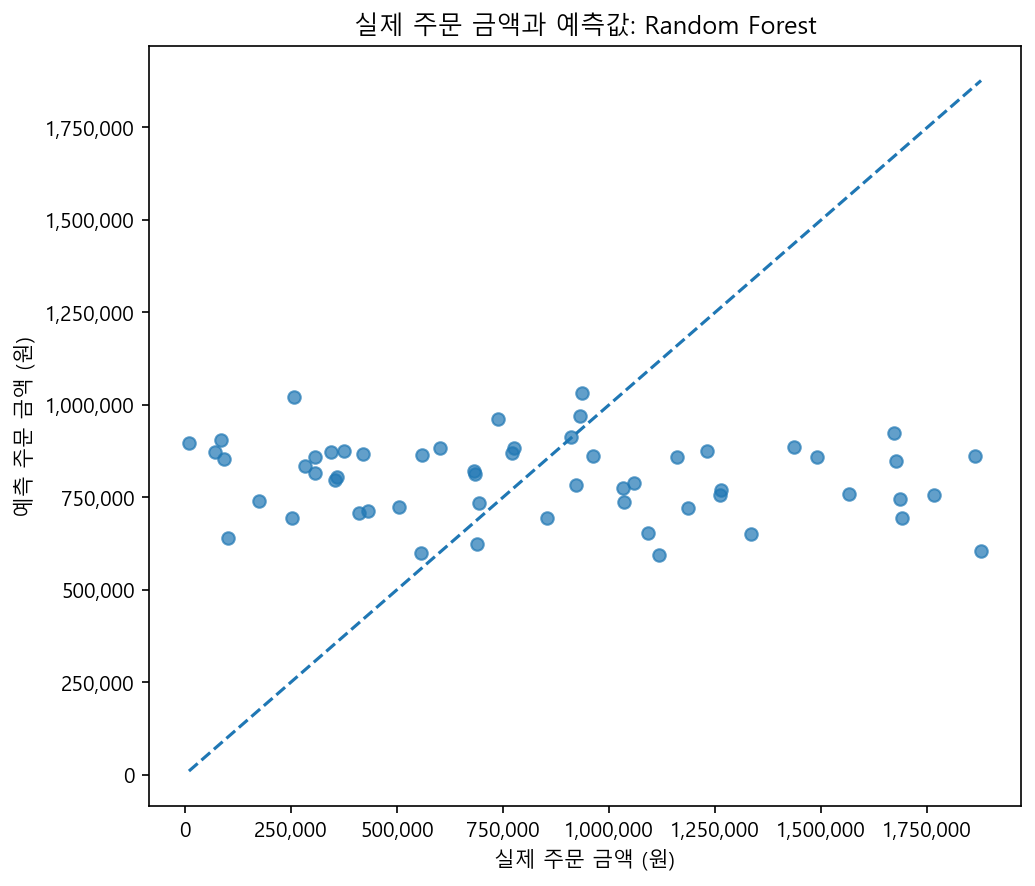

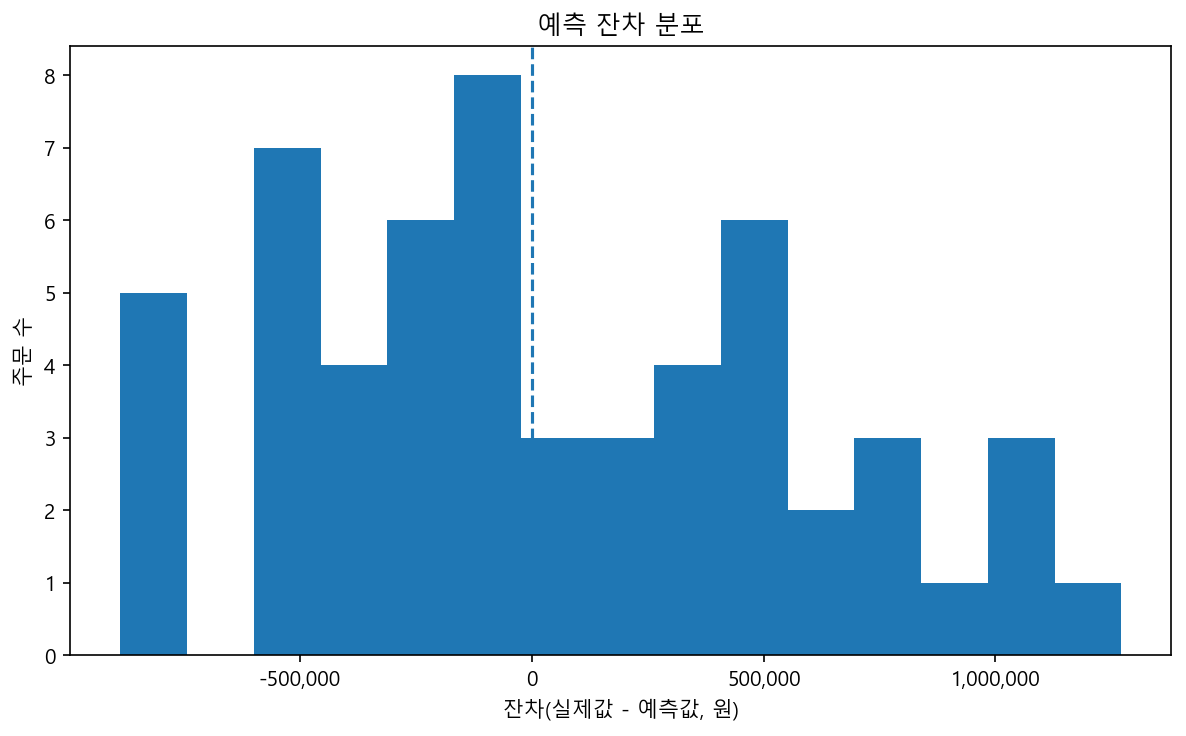

In [16]:
from IPython.display import Image, display
import shutil
(PROJECT_ROOT / 'images').mkdir(exist_ok=True)
for source, target in [('ch09_actual_vs_predicted.png','graph01.png'), ('ch09_residual_histogram.png','graph02.png')]:
    path = REPORT_DIR / 'figures' / source
    shutil.copy2(path, PROJECT_ROOT / 'images' / target)
    display(Image(data=path.read_bytes(), width=850))

## 13. 전체 공통 함수를 새 실행으로 다시 확인합니다

셀의 메모리 상태가 아니라 공통 함수가 같은 순서를 재현하는지 확인합니다.

In [17]:
import os
import subprocess
snapshot = {
    'ch09_regression_cv_summary.csv': cv_summary.copy(deep=True),
    'ch09_regression_model_comparison.csv': model_comparison.copy(deep=True),
    'ch09_regression_split_summary.csv': split_summary.copy(deep=True),
    'ch09_regression_predictions_public.csv': public_prediction_result(prediction_result).copy(deep=True),
}
env = {**os.environ, 'PYTHONIOENCODING': 'utf-8', 'MPLBACKEND': 'Agg'}
logs = []
for filename in ['prepare_ch09_data.py', 'run_regression_analysis.py', 'verify_ch09.py']:
    completed = subprocess.run([sys.executable, str(PROJECT_ROOT / 'scripts' / filename)], cwd=PROJECT_ROOT, env=env, capture_output=True, text=True, encoding='utf-8')
    logs.append(f'[{filename}] exit code = {completed.returncode}\n{completed.stdout}\n{completed.stderr}')
    print(logs[-1])
    assert completed.returncode == 0, filename
for filename, frame in snapshot.items():
    saved = pd.read_csv(REPORT_DIR / filename)
    expected = frame.copy()
    for column in expected.select_dtypes(include=['datetime']).columns:
        expected[column] = expected[column].dt.strftime('%Y-%m-%d')
    pd.testing.assert_frame_equal(expected.reset_index(drop=True), saved.reset_index(drop=True), check_dtype=False, check_exact=False, rtol=1e-8, atol=1e-6)
print('Notebook vs separate process: all four tables MATCH')
display(pd.read_csv(REPORT_DIR / 'ch09_regression_validation.csv'))
(REPORT_DIR / 'ch09_reproduction_log.txt').write_text('\n'.join(logs) + '\nNotebook vs separate process: all four tables MATCH', encoding='utf-8')

[prepare_ch09_data.py] exit code = 0
Chapter09 모델링 입력 준비 완료
입력 Raw 경로: C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\data\raw

[관계 검증]
                                               check  invalid_count
  orders.customer_id exists in customers.customer_id              0
      order_items.order_id exists in orders.order_id              0
order_items.product_id exists in products.product_id              0

[저장된 processed 파일]
- C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\data\processed\customers_clean.csv
- C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\data\processed\products_clean.csv
- C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\data\processed\orders_clean.csv
- C:\Users\신윤철\Documents\llm-data-analysis-study\chapter09\data\processed\order_items_clean.csv




[run_regression_analysis.py] exit code = 0
9장 회귀 분석 완료

[시간 순서 분할]
split  rows  ratio_pct start_date   end_date
train   244      81.33 2025-07-09 2026-04-13
 test    56      18.67 2026-04-14 2026-07-08

[Feature Audit]
         column  selected            role                   reason
    order_month      True allowed_feature   교육용 예측 시점에 사용 가능하다고 가정
order_dayofweek      True allowed_feature   교육용 예측 시점에 사용 가능하다고 가정
            age      True allowed_feature   교육용 예측 시점에 사용 가능하다고 가정
 payment_method      True allowed_feature   교육용 예측 시점에 사용 가능하다고 가정
         gender      True allowed_feature   교육용 예측 시점에 사용 가능하다고 가정
           city      True allowed_feature   교육용 예측 시점에 사용 가능하다고 가정
 avg_unit_price     False       forbidden      주문 상세에서 만든 목표 대리 변수
    customer_id     False       forbidden                   고객 식별자
     item_count     False       forbidden  주문 상세가 확인된 뒤 계산되는 사후 집계
     line_total     False       forbidden       목표값을 구성하는 주문 상세 금액
       order_id     False       forbidden   

[verify_ch09.py] exit code = 0
                        check status
  raw_unchanged_customers.csv   PASS
raw_unchanged_order_items.csv   PASS
     raw_unchanged_orders.csv   PASS
   raw_unchanged_products.csv   PASS
  all_order_targets_match_raw   PASS
                 strict_dates   PASS
              train_test_rows   PASS
      train_cv_selected_model   PASS
         feature_overlap_zero   PASS
   forbidden_feature_rejected   PASS
      baseline_cv_independent   PASS
           exact_final_models   PASS
 prediction_covers_final_test   PASS
prediction_actual_matches_raw   PASS
           residual_abs_error   PASS
         baseline_all_metrics   PASS
         selected_all_metrics   PASS
          improvement_formula   PASS
          public_columns_safe   PASS
          official_validation   PASS
Independent validation: 20 PASS


Notebook vs separate process: all four tables MATCH


,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


6811

## 14. 해석

낮은 성능이나 음수 R²도 숨기지 않습니다. 현재 예측 시점에 허용한 정보가 약하다면 `현재 데이터로는 모델 사용 보류`도 올바른 결론입니다.

LLM이 만든 코드도 같은 예측 시점·누수·Pipeline·Train CV·Final Test 보호 기준으로 검토합니다.

## 15. 완료 체크

- [x] `python scripts/prepare_ch09_data.py`로 공통 모델링 입력을 준비했다.
- [x] Target과 예측 시점을 설명할 수 있다.
- [x] 금지 feature가 입력에 없음을 확인했다.
- [x] 같은 날짜가 Train과 Final Test에 동시에 들어가지 않는다.
- [x] 전처리는 Pipeline 내부에서 학습된다.
- [x] Train TimeSeriesSplit으로 후보를 비교했다.
- [x] Final Test 전에 Selected Model을 고정했다.
- [x] Final Test에서는 Baseline과 Frozen Model만 비교했다.
- [x] MAE, RMSE, R²를 함께 읽었다.
- [x] 내부 식별자 결과와 공개 보고서를 구분했다.
- [x] Validation Evidence가 모두 PASS다.

# 제출 답안: Chapter 09 회귀 분석

## 제출 정보
- 이름: 신윤철
- GitHub ID: ycshin2002
- 작성일: 2026-11-05
- 최종 Notebook URL: https://github.com/ycshin2002/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb

## 1. 예측 문제 정의
- Target: order_total, 같은 order_id의 quantity×unit_price 합계(원).
- 예측 단위: 주문 1건. 전체 300건을 대상으로 하며 Chapter08과 달리 completed 주문만으로 필터링하지 않는다.
- 예측 시점: 결제수단을 선택하여 주문 메타데이터와 등록 프로필은 있지만 주문 상세 수량·단가·금액은 모델에 전달되지 않은 교육용 시점.
- 알 수 있는 정보: 주문 월·요일, 등록 나이·성별·도시, 선택한 결제수단.
- 알 수 없는 정보: 상세 수량·가격·금액과 그 파생 집계, 최종 주문 상태.
### 나의 해석과 판단
Target을 직접 계산하는 재료 없이 사전 정보만으로 미래 주문 금액을 추정하는 문제로 고정했다. 실제 서비스에서 결제수단이나 프로필을 그 시점에 조회할 수 없다면 해당 Feature도 제외해야 한다. 특히 이 문제는 장바구니가 확정되어 금액이 이미 알려진 상황과는 다르다. 원본에는 프로필 변경 이력이 없어 나이·도시의 시점 일치도는 교육용 가정이며 실제 배포 전 확인해야 한다.

## 2. Feature Leakage Audit
| feature | 예측 시점 사용 가능 | Target 계산 재료 | 사후 정보/ID | 최종 사용 | 판단 이유 |
| --- | --- | --- | --- | --- | --- |
| order_month | 조건부 예 | 아니오 | 아니오 | 사용 | 현재 날짜에서 계산 |
| order_dayofweek | 조건부 예 | 아니오 | 아니오 | 사용 | 현재 날짜에서 계산 |
| age | 조건부 예 | 아니오 | 아니오 | 사용 | 예측 시점에 등록된 나이라고 가정 |
| payment_method | 조건부 예 | 아니오 | 아니오 | 사용 | 사용자가 결제수단을 선택한 후라고 가정 |
| gender | 조건부 예 | 아니오 | 아니오 | 사용 | 예측 시점에 등록된 프로필이라고 가정 |
| city | 조건부 예 | 아니오 | 아니오 | 사용 | 예측 시점의 등록 도시라고 가정 |
| order_total | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | Target 자체라 정답을 입력하는 셈 |
| line_total | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | Target을 직접 구성하는 금액 |
| quantity | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | Target 계산 재료, 상세 미제공 시점에 알 수 없음 |
| unit_price | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | Target 계산 재료, 상세 미제공 시점에 알 수 없음 |
| item_count | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | 상세가 확인된 뒤 계산하는 집계 |
| total_quantity | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | 상세 기반 Target 대리 변수 |
| avg_unit_price | 사용 불가 | 예/직간접 | 상세 확정 후 | 제외 | 상세 기반 Target 대리 변수 |
| order_status | 사용 불가 | 아니오 | 예 | 제외 | 완료·취소·환불은 사후 확정 정보 |
| order_id | 사용 불가 | 아니오 | 예 | 제외 | 주문 식별자이며 일반화 가능한 수치가 아님 |
| customer_id | 사용 불가 | 아니오 | 예 | 제외 | 고객 식별자를 외우게 할 수 있음 |
| product_id | 사용 불가 | 아니오 | 예 | 제외 | 상세에 속한 식별자이며 현재 시점의 입력이 아님 |

- 금지 Feature overlap: 0개.
- 가장 위험한 Feature: line_total 및 total_quantity 같은 Target 대리 변수. 단순한 상관 정보가 아니라 정답을 구성하거나 상세 확정 후 생성되는 정보라 제외했다.
- 스크린샷 위치: 본문 **4. Feature Audit을 확인합니다**. 파일명 `images/step02_leakage.png`.

## 3. Target 생성과 관계 검증
### 계산 기준
`line_total = quantity × unit_price`, `order_total = order_id별 line_total 합계`.
- 전체 상세 764행의 기존 line_total 불일치 0건, Target은 주문별 300행.
- orders↔target: outer merge + one_to_one + indicator로 양쪽 미매칭 0, 300→300행.
- orders→customers: many_to_one, 미매칭 0, 300→300행. 부모 PK 결측·중복도 점검했다.
- 공통 Raw의 고객/주문/상품 FK 미매칭도 모두 0이다.
### 나의 해석과 판단
중복 키는 주문 행을 늘려 표본과 금액을 중복시킬 수 있고, inner merge는 상세가 없는 주문을 조용히 없앨 수 있다. 모델을 만들기 전에 이러한 관계를 차단했다. 원본 파일의 SHA-256과 주문별 Target도 독립 재계산으로 대조했다.

## 4. Train / Final Test 분할
| split | rows | ratio_pct | start_date | end_date |
| --- | --- | --- | --- | --- |
| train | 244.00 | 81.33 | 2025-07-09 | 2026-04-13 |
| test | 56.00 | 18.67 | 2026-04-14 | 2026-07-08 |
- Train: 2025-07-09~2026-04-13, 244건.
- Final Test: 2026-04-14~2026-07-08, 56건.
- 같은 달력 날짜 중복: 없음. Train 최종 날짜 < Test 최초 날짜.
### 분할 판단
미래에 예측할 상황을 모방하려 과거로 학습하고 뒤 기간을 남겼다. 고유 날짜 기준 80:20 분할이라 행 비율은 정확한 80:20이 아닌 81.33:18.67이다. 고객 ID는 입력이 아니지만 반복 고객이 두 기간에 있을 수 있어 이 평가는 신규 고객 일반화를 별도로 증명하지 않는다.
- 스크린샷 위치: 본문 **5. 시간 순서로 Train / Final Test를 분리합니다**. `images/step04_split.png`.

## 5. Train TimeSeriesSplit 후보 비교
| model | n_splits | cv_MAE_mean | cv_MAE_std | cv_R2_mean |
| --- | --- | --- | --- | --- |
| Baseline Mean | 5.00 | 423,004.81 | 44,153.04 | -0.02 |
| Random Forest | 5.00 | 437,352.80 | 26,318.79 | -0.11 |
| Linear Regression | 5.00 | 461,386.29 | 77,792.80 | -0.31 |
### Train CV로 선택한 비베이스라인 모델
- Selected Model: Random Forest.
- 선택 기준: Linear Regression과 Random Forest 중 Train 5-fold TimeSeriesSplit의 CV MAE 평균이 작은 모델. 후보·하이퍼파라미터·seed=42는 공식값을 고정했다.
- Final Test 전에 선택했는가: 예. 본문 **8. 비베이스라인 모델 선택을 고정합니다**에서 Train CV만으로 JSON을 저장한 뒤 **9**에서 최종 평가한다. 별도 실행 스크립트도 동일 순서다.
### 나의 해석과 판단
Random Forest의 CV MAE는 437,352.80원, 표준편차는 26,318.79원이다. Linear Regression보다 낮지만 Baseline의 423,004.81원보다 나쁘므로 선택됐다는 사실이 사용 가치까지 보장하지 않는다. 표준편차는 시간 구간별 성능 변동을 보여 주며 신뢰구간이나 통계적 유의성으로 해석하지 않았다.

숫자형은 median imputation→StandardScaler, 범주형은 most-frequent imputation→OneHotEncoder(handle_unknown='ignore')를 각 Pipeline 안에서 fit했다. Test에는 transform/predict만 한다. 공통 전처리의 전체 고객 나이 중앙값 대체는 Chapter09 준비 단계에서 되돌려, 결측이 생겨도 각 Train Fold 안에서만 대체값을 학습하도록 했다. 이번 원본의 나이 결측은 0이라 해당 보완이 결과 숫자를 바꾸지 않는다. 날짜 파생·문자열 공백 정리 같은 결정적 변환은 전체 입력에 적용해도 학습 통계를 사용하지 않는다.

공식 CV는 날짜·ID로 정렬한 **행 기준** TimeSeriesSplit이다. 같은 달력 날짜가 일부 인접 CV Fold 경계에 걸릴 수 있고 불규칙한 주문 간격이라 Fold 기간 길이도 다르다. 이는 Final Test의 날짜 중복 0과 별개의 한계이며 `ch09_cv_fold_checks.csv`에 기록했다. 이번 Final Test를 본 뒤 분할이나 후보를 변경하지 않았다.

## 6. Final Test: Baseline vs Frozen Model
| model | selection_role | train_MAE | test_MAE | test_RMSE | test_R2 | MAE_improvement_vs_baseline_pct |
| --- | --- | --- | --- | --- | --- | --- |
| Baseline Mean | baseline | 416,266.19 | 443,449.65 | 522,189.70 | -0.00 | 0.00 |
| Random Forest | selected_by_train_cv | 326,438.48 | 458,819.92 | 548,190.45 | -0.10 | -3.47 |
- 스크린샷 위치: 본문 **9. 이제 Final Test에서 Baseline과 고정 모델만 평가합니다**. `images/step06_final_metrics.png`.
### 결과 관찰
Frozen Random Forest의 MAE는 458,819.92원으로 Baseline 443,449.65원보다 나쁘다. MAE 개선율 -3.47%는 약 3.47% **악화**라는 뜻이다. 다른 후보의 Final Test 성능은 계산해 모델 선택에 사용하지 않았다.
### 나의 해석과 판단
- MAE: 개별 주문 금액을 평균적으로 약 45.9만 원 틀린다. 상대 오차율이나 모든 주문의 오차 상한이 아니다.
- RMSE: 548,190.45원으로 MAE보다 커, 일부 큰 오차의 영향이 있다.
- R²: -0.1033. 이 Test의 **실제값 평균**을 항상 예측하는 기준보다 제곱오차가 크다. 학습 평균으로 예측하는 Dummy Baseline과 R²의 0 기준은 정확히 같지 않다. 음수는 코드 오류의 증명이 아니다.
- Train MAE 326,438.48원보다 Test MAE가 커 학습 기간 성능을 미래 성능으로 대체할 수 없다.
### 업무·분석적 의미
현재 정보와 모델 복잡성이 평균 예측보다 미래 오차를 줄였다는 근거가 없다. 높은 주문 금액에 대한 개별 의사결정이나 자동 운영에 쓰지 않는다. 한 Test 기간의 차이를 통계적 유의성이 입증된 결과라고 주장하지 않는다.

## 7. 대표 오차 사례
### 사례 1
- 실제값: 1,877,000원.
- 예측값: 605,528.72원.
- residual(실제−예측): 1,271,471.28원.
- absolute error: 1,271,471.28원.
- 관찰: 실제 고액 주문을 낮게 추정했다. 원본 주문 ID 대신 오차 순위로 사례를 표시했다.
- 가능한 이유 후보: 상세 수량·가격 없이 메타데이터만 사용하는 정보 제한 때문에 고액 주문을 구별하기 어려웠을 수 있다. 실제 원인으로 단정하지 않는다.
- 추가 확인: 예측 당시 기록의 정확성과 상품 구성·수량별 차이를 사후 진단으로 확인하되, 이 예측 시점의 Feature에 금지된 상세를 다시 넣지는 않는다.
- 모델 한계: 개별 고액 주문 오차가 약 100만 원 이상이므로 개인별 금액 의사결정에 위험하다.

### 사례 2
- 실제값: 1,767,000원.
- 예측값: 756,889.65원.
- residual(실제−예측): 1,010,110.35원.
- absolute error: 1,010,110.35원.
- 관찰: 실제 고액 주문을 낮게 추정했다. 원본 주문 ID 대신 오차 순위로 사례를 표시했다.
- 가능한 이유 후보: 상세 수량·가격 없이 메타데이터만 사용하는 정보 제한 때문에 고액 주문을 구별하기 어려웠을 수 있다. 실제 원인으로 단정하지 않는다.
- 추가 확인: 예측 당시 기록의 정확성과 상품 구성·수량별 차이를 사후 진단으로 확인하되, 이 예측 시점의 Feature에 금지된 상세를 다시 넣지는 않는다.
- 모델 한계: 개별 고액 주문 오차가 약 100만 원 이상이므로 개인별 금액 의사결정에 위험하다.

### 사례 3
- 실제값: 1,863,000원.
- 예측값: 861,784.71원.
- residual(실제−예측): 1,001,215.29원.
- absolute error: 1,001,215.29원.
- 관찰: 실제 고액 주문을 낮게 추정했다. 원본 주문 ID 대신 오차 순위로 사례를 표시했다.
- 가능한 이유 후보: 상세 수량·가격 없이 메타데이터만 사용하는 정보 제한 때문에 고액 주문을 구별하기 어려웠을 수 있다. 실제 원인으로 단정하지 않는다.
- 추가 확인: 예측 당시 기록의 정확성과 상품 구성·수량별 차이를 사후 진단으로 확인하되, 이 예측 시점의 Feature에 금지된 상세를 다시 넣지는 않는다.
- 모델 한계: 개별 고액 주문 오차가 약 100만 원 이상이므로 개인별 금액 의사결정에 위험하다.


양의 residual은 과소예측, 음의 residual은 과대예측이다. 고액 주문만 틀리는 것은 아니며 10,000원 주문을 약 897,415원으로 과대예측한 사례도 있다. 사후 오류 진단은 가능하지만 이를 바탕으로 이번 Final Test에 맞춰 모델을 다시 선택하지 않는다.

## 8. Validation Evidence
| check | value | status |
| --- | --- | --- |
| forbidden_feature_overlap | 0 | PASS |
| strict_train_before_test | True | PASS |
| selected_model_exists_in_train_cv | True | PASS |
| final_test_contains_baseline | True | PASS |
| final_test_contains_frozen_selected_model | True | PASS |
| test_rows_for_r2 | 56 | PASS |
### FAIL 항목
없음. 공식 자동 Validation 6개 모두 PASS다. 독립 검증에서 Target·분할·Baseline CV·최종 지표·개선율·공개 컬럼도 다시 확인했다. PASS는 절차를 지켰다는 뜻이지 모델 성능이 좋다는 뜻은 아니다.

## 9. Evidence와 공개 범위
### 생성된 Evidence
- [x] ch09_regression_split_summary.csv
- [x] ch09_regression_feature_audit.csv
- [x] ch09_regression_cv_summary.csv
- [x] ch09_regression_model_comparison.csv
- [x] ch09_regression_validation.csv
- [x] ch09_regression_checklist.csv
### Internal 파일
- [x] ch09_regression_model_data_internal.csv
- [x] ch09_regression_predictions_internal.csv
두 파일은 로컬에서 생성되지만 `.gitignore`의 `reports/*_internal.csv`로 Git 커밋에서 제외된다.
### 공개 결과
- [x] ch09_regression_report.md
- [x] ch09_actual_vs_predicted.png
- [x] ch09_residual_histogram.png
- [x] ch09_regression_predictions_public.csv (원본 주문 ID 제거)
### 공개 범위 판단
ID는 다른 파일과 연결해 개별 주문·고객을 추적하는 키가 될 수 있다. 모델 입력에서 제외하는 것과 공개 결과에서 제거하는 것은 별개라 둘 다 점검했다. 제공 원본은 공식 가상 데이터이지만 실제 데이터에서도 원본을 공개해도 된다는 의미는 아니다. 공개 출력은 직접 ID를 제거한 요약·진단이며 엄밀한 재식별 불가능성을 보장하지 않는다.

## 10. 최종 사용 판단
- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] 현재 데이터로는 사용 보류
### 판단 근거
1. Train CV에서 두 비베이스라인 후보가 모두 Baseline보다 MAE가 나빴다. Random Forest가 후보 중 선택된 것일 뿐 Baseline을 이기지 못했다.
2. Final Test에서도 MAE 약 45.9만 원, RMSE 약 54.8만 원, R² 약 -0.1033이고 Baseline 대비 3.47% 악화됐다.
3. Feature 누수·최종 시간 분할 검증은 PASS지만, 고액·저액 주문을 모두 크게 틀리는 사례가 있어 실사용 위험이 크다.
### 업무적 위험
고객별 예상 금액으로 예산·혜택·위험도를 자동 결정하면 큰 오차와 프로필 기반 편향을 전파할 수 있다. 성별·나이 같은 변수의 필요성·공정성도 별도로 검토해야 한다.
### 현재 데이터의 한계
가상 데이터 300건, 최종 테스트 56건으로 작다. 월·요일·프로필·결제수단만으로 상세 금액을 설명하기 어려우며 실제 서비스 대표성·시점별 프로필·분포 변화는 확인되지 않았다. 여러 CV Fold에서 같은 날의 주문이 양쪽에 걸릴 수 있는 한계도 남는다.
### 다음 개선 우선순위
1. 예측 시점에 실제로 존재하는 Feature와 프로필 이력을 확인하고 표본을 늘린다. 상세 재료를 몰래 추가하지 않는다.
2. 날짜 단위 CV와 추가 미래 기간·신규 고객 평가를 **새로운 보호 평가 구간**에서 설계한다.
3. 안전한 사전 정보가 확보되면 Train 내부에서만 후보를 검토하고 이번 Final Test는 재사용하지 않는다.

## 11. 전체 재실행 확인
`python scripts/prepare_ch09_data.py` → `python scripts/run_regression_analysis.py` → `python scripts/verify_ch09.py`를 본문 **13**에서 동일 Python의 별도 프로세스로 실행한다.
- 실행 성공 여부: 모두 종료 코드 0.
- Train CV Selected Model: Random Forest.
- Final Validation: 6개 모두 PASS.
- Notebook과 스크립트의 CV·최종 지표·시간 분할·공개 예측값: 허용 오차 내 일치.
- 같은 고정 설정을 재현한 것이며 반복 결과를 보고 모델·Feature를 바꾸지 않았다.

## 12. LLM 활용 및 검증
- 사용 목적: 코드·경로 구성, 누수 점검, 지표·오차 해석 초안 작성.
- Prompt 요약: 공식 Chapter09 순서를 유지해 실행 노트북과 증빙을 작성하고 결과를 실제 데이터로 검증하도록 요청했다.
- 제안/반영: Pipeline 내 결측 대체, Train CV만의 선택, 선택 JSON 사전 저장, 공개 ID 제거, 별도 프로세스 재현을 반영했다.
- 수정/보류: Target 대리 Feature, Test를 보고 다른 모델로 교체, 약한 성능을 성공으로 표현하는 해석은 제외했다.
- 검증 근거: 실제 CV·최종 Test CSV, 공식 Validation, 독립 지표 재계산, 재실행 로그. 자동 검증은 AI가 수행했고 제출자의 수동 검토는 아직 별도로 필요하다.
- Safe Context: 코드·스키마·집계·ID 제거 진단만 사용했다. 원본 고객 행·개인 식별정보를 Prompt로 제공하지 않았다.

## 최종 체크
- [x] Target과 예측 시점을 정의하고 Leakage Audit을 수행했다.
- [x] Target·관계·시간 분할·Pipeline 내부 전처리를 확인했다.
- [x] Train CV에서 선택을 고정한 뒤 Final Test를 평가했다.
- [x] Baseline과 비교하고 낮은 성능·음수 R²를 숨기지 않았다.
- [x] 대표 오차·한계·사용 보류 판단을 작성했다.
- [x] Validation 6개 PASS, 공개/내부 결과 구분, 별도 재실행을 확인했다.
- [ ] 제출자 수동 검토와 필요한 캡처를 완료했다.
- [ ] GitHub 최종 표시 확인 후 Notebook URL을 LMS에 제출했다.

## 캡처 이미지 최신본 확인 (선택)
아래 파일을 images에 저장한 뒤 이 셀만 재실행하고 Ctrl+S로 저장하면 최신 캡처가 Notebook 출력에 내장된다. 캡처가 없어도 위의 실제 실행 출력은 남아 있다.

In [18]:
from IPython.display import Image, display
for filename in ['step02_leakage.png','step04_split.png','step06_final_metrics.png']:
    path = PROJECT_ROOT / 'images' / filename
    if path.exists():
        print(filename)
        display(Image(data=path.read_bytes(), width=1000))
    else:
        print('선택 캡처 대기:', filename)

선택 캡처 대기: step02_leakage.png
선택 캡처 대기: step04_split.png
선택 캡처 대기: step06_final_metrics.png
